# How missing roads change evacuation exits: a small test in Paradise, California

**Question.** If some streets are missing from a road map, how much does that change which exits look busiest, and how many intersections can still reach an exit?

**Method.** I downloaded the Paradise, California road network from OpenStreetMap using OSMnx in Python. Intersections inside the town boundary stand in for homes, and nodes just outside it, at the far ends of roads crossing the boundary, are treated as exits. Each intersection is routed to its nearest exit, and the intersections using each exit are counted. I then removed 5%, 10%, 20%, and 30% of street segments, either at random (20 repeats per level) or the busiest streets according to the baseline routes, and compared the results with the baseline using the Spearman rank correlation of exit loads and the share of intersections cut off.

**Results.** At every level tested, removing the busiest streets disrupted the exit ranking more than any of 20 random removals of the same size (for example, Spearman 0.28 at 5% against 0.68 to 0.97 for random removals). It also cut off more intersections than the random average at every level, and more than any random run at 5%, 20%, and 30% (at 10% it fell inside the random range). At high removal levels most intersections lose every route, so the Spearman values there rest on few remaining intersections.

**Limits.** One town; intersections stand in for homes, with no population data; exits are a simplified definition; a removed street is unavailable in both directions; and the busiest-street case is a deliberately constructed worst case, not a prediction. This is a simplified exercise inspired by Murray (2025), not a replication of that model.

In [12]:
!pip install osmnx

In [13]:
import osmnx as ox

place = "Paradise, California, USA"
G = ox.graph_from_place(place,network_type="drive",truncate_by_edge=True)

print("Intersections:", len(G.nodes))
print("Road pieces:", len(G.edges))

Intersections: 1852
Road pieces: 4099


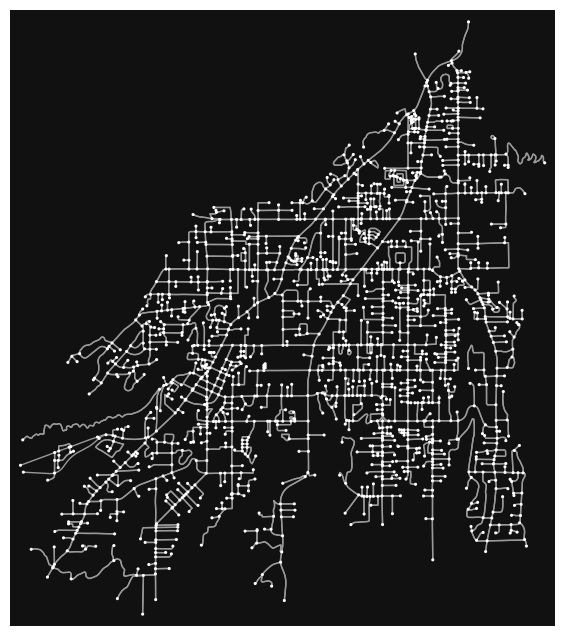

(<Figure size 800x800 with 1 Axes>,
 <Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>)

In [14]:
ox.plot_graph(G, node_size=5)

In [15]:
boundary = ox.geocode_to_gdf(place).geometry.iloc[0]
nodes = ox.graph_to_gdfs(G, edges=False)

inside = nodes.within(boundary)
exit_nodes = list(nodes[~inside].index)
home_nodes=list(nodes[inside].index)

print("Homes (intersections inside town):", len(home_nodes))
print("Exits (intersections outside town):", len(exit_nodes))

Homes (intersections inside town): 1822
Exits (intersections outside town): 30


In [16]:
import networkx as nx
from collections import Counter

Gr = G.reverse(copy=True)
dist, paths = nx.multi_source_dijkstra(Gr, sources=exit_nodes, weight="length")

exit_load = Counter()
for h in home_nodes:
    if h in paths:
        exit_load[paths[h][0]] += 1

print("Homes with a route out:", sum(exit_load.values()), "of", len(home_nodes))
print("Busiest exits (exit id, homes using it):")
for node, count in exit_load.most_common(10):
    print(node, count)

Homes with a route out: 1822 of 1822
Busiest exits (exit id, homes using it):
86480320 454
86475701 344
86500303 272
86431098 161
86518494 147
5659704596 112
86520777 104
86526034 74
86502126 55
86387168 43


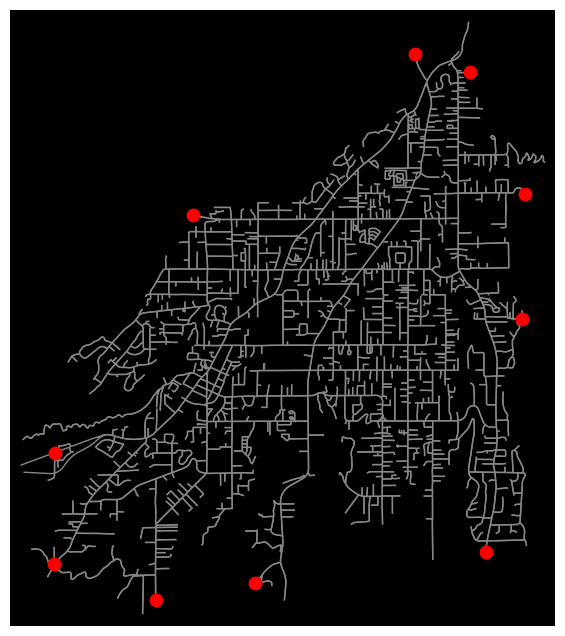

In [17]:
baseline_load = dict(exit_load)

import matplotlib.pyplot as plt

top = [n for n, c in exit_load.most_common(10)]
fig, ax = ox.plot_graph(G, show=False, close=False, node_size=0,
                        edge_color="#888888", bgcolor="black")
ax.scatter([G.nodes[n]["x"] for n in top],
           [G.nodes[n]["y"] for n in top],
           c="red", s=80, zorder=3)
plt.show()

In [18]:
import random
import numpy as np
from scipy.stats import spearmanr

def get_exit_load(graph):
    gr = graph.reverse(copy=True)
    d, p = nx.multi_source_dijkstra(gr, sources=exit_nodes, weight="length")
    load = Counter()
    for h in home_nodes:
        if h in p:
            load[p[h][0]] += 1
    return load, sum(load.values())

def remove_links(graph, edge_list):
    H = graph.copy()
    for u, v, k in edge_list:
        if H.has_edge(u, v, k):
            H.remove_edge(u, v, k)
        if H.has_edge(v, u):
            first_key = list(H[v][u].keys())[0]
            H.remove_edge(v, u, first_key)
    return H

In [19]:
def remove_segments(graph, segment_list):
    H = graph.copy()
    for u, v in segment_list:
        while H.has_edge(u, v):
            H.remove_edge(u, v)
        while H.has_edge(v, u):
            H.remove_edge(v, u)
    return H

segments = list({tuple(sorted((u, v))) for u, v, k in G.edges(keys=True) if u != v})
print("Street segments in the map:", len(segments))
random.seed(42)

for frac in [0.05, 0.10, 0.20, 0.30]:
    cors, unreachable = [], []
    for run in range(20):
        drop = random.sample(segments, int(len(segments) * frac))
        H = remove_segments(G, drop)
        load, reached = get_exit_load(H)
        a = [baseline_load.get(x, 0) for x in exit_nodes]
        b = [load.get(x, 0) for x in exit_nodes]
        cors.append(spearmanr(a, b)[0])
        unreachable.append(1 - reached / len(home_nodes))
    print(f"{int(frac*100)}% of street segments removed: ranking match = {np.nanmean(cors):.2f}, homes cut off = {np.nanmean(unreachable)*100:.1f}%")

Street segments in the map: 2020
5% of street segments removed: ranking match = 0.89, homes cut off = 9.0%
10% of street segments removed: ranking match = 0.86, homes cut off = 23.6%
20% of street segments removed: ranking match = 0.75, homes cut off = 78.7%
30% of street segments removed: ranking match = 0.66, homes cut off = 93.0%


In [20]:
Gr0 = G.reverse(copy=True)
d0, p0 = nx.multi_source_dijkstra(Gr0, sources=exit_nodes, weight="length")

seg_load = Counter()
for h in home_nodes:
    route = p0[h]
    for i in range(len(route) - 1):
        seg_load[tuple(sorted((route[i], route[i + 1])))] += 1

print("Segments used by at least one route:", len(seg_load), "of", len(segments))

a = [baseline_load.get(x, 0) for x in exit_nodes]
for frac in [0.05, 0.10, 0.20, 0.30]:
    k = int(len(segments) * frac)
    busiest = [s for s, c in seg_load.most_common(k)]
    H = remove_segments(G, busiest)
    load, reached = get_exit_load(H)
    b = [load.get(x, 0) for x in exit_nodes]
    print(f"{int(frac*100)}% BUSIEST segments removed ({len(busiest)}): ranking match = {spearmanr(a, b)[0]:.2f}, homes cut off = {(1 - reached / len(home_nodes))*100:.1f}%")

Segments used by at least one route: 1822 of 2020
5% BUSIEST segments removed (101): ranking match = 0.28, homes cut off = 17.8%
10% BUSIEST segments removed (202): ranking match = 0.20, homes cut off = 30.9%
20% BUSIEST segments removed (404): ranking match = 0.08, homes cut off = 97.7%
30% BUSIEST segments removed (606): ranking match = 0.05, homes cut off = 98.6%


5% random (20 runs): Spearman = 0.89 (SD 0.08, range 0.68 to 0.97); intersections cut off = 9.0% (SD 1.8, range 6.7 to 13.6)
10% random (20 runs): Spearman = 0.86 (SD 0.09, range 0.58 to 0.97); intersections cut off = 23.6% (SD 5.7, range 15.4 to 34.6)
20% random (20 runs): Spearman = 0.75 (SD 0.10, range 0.48 to 0.92); intersections cut off = 78.7% (SD 10.7, range 55.3 to 96.7)
30% random (20 runs): Spearman = 0.66 (SD 0.15, range 0.32 to 0.88); intersections cut off = 93.0% (SD 2.4, range 86.0 to 96.5)
5% busiest: Spearman = 0.28; intersections cut off = 17.8%
10% busiest: Spearman = 0.20; intersections cut off = 30.9%
20% busiest: Spearman = 0.08; intersections cut off = 97.7%
30% busiest: Spearman = 0.05; intersections cut off = 98.6%


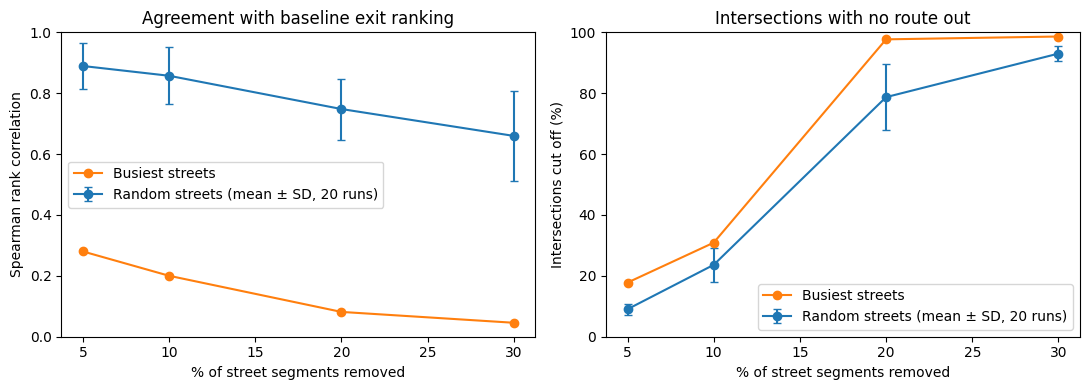

In [21]:
levels = [0.05, 0.10, 0.20, 0.30]
a = [baseline_load.get(x, 0) for x in exit_nodes]
random.seed(42)

rand_rho, rand_rho_sd, rand_cut, rand_cut_sd = [], [], [], []
for frac in levels:
    rho, cut = [], []
    for run in range(20):
        drop = random.sample(segments, int(len(segments) * frac))
        H = remove_segments(G, drop)
        load, reached = get_exit_load(H)
        b = [load.get(x, 0) for x in exit_nodes]
        rho.append(spearmanr(a, b)[0])
        cut.append((1 - reached / len(home_nodes)) * 100)
    rand_rho.append(np.nanmean(rho)); rand_rho_sd.append(np.nanstd(rho))
    rand_cut.append(np.mean(cut)); rand_cut_sd.append(np.std(cut))
    print(f"{int(frac*100)}% random (20 runs): Spearman = {np.nanmean(rho):.2f} (SD {np.nanstd(rho):.2f}, range {np.nanmin(rho):.2f} to {np.nanmax(rho):.2f}); intersections cut off = {np.mean(cut):.1f}% (SD {np.std(cut):.1f}, range {min(cut):.1f} to {max(cut):.1f})")

targ_rho, targ_cut = [], []
for frac in levels:
    k = int(len(segments) * frac)
    busiest = [s for s, c in seg_load.most_common(k)]
    H = remove_segments(G, busiest)
    load, reached = get_exit_load(H)
    b = [load.get(x, 0) for x in exit_nodes]
    targ_rho.append(spearmanr(a, b)[0])
    targ_cut.append((1 - reached / len(home_nodes)) * 100)
    print(f"{int(frac*100)}% busiest: Spearman = {targ_rho[-1]:.2f}; intersections cut off = {targ_cut[-1]:.1f}%")

pct = [int(f * 100) for f in levels]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].errorbar(pct, rand_rho, yerr=rand_rho_sd, marker="o", capsize=3, label="Random streets (mean ± SD, 20 runs)")
axes[0].plot(pct, targ_rho, marker="o", label="Busiest streets")
axes[0].set_title("Agreement with baseline exit ranking")
axes[0].set_xlabel("% of street segments removed")
axes[0].set_ylabel("Spearman rank correlation")
axes[0].set_ylim(0, 1)
axes[0].legend()
axes[1].errorbar(pct, rand_cut, yerr=rand_cut_sd, marker="o", capsize=3, label="Random streets (mean ± SD, 20 runs)")
axes[1].plot(pct, targ_cut, marker="o", label="Busiest streets")
axes[1].set_title("Intersections with no route out")
axes[1].set_xlabel("% of street segments removed")
axes[1].set_ylabel("Intersections cut off (%)")
axes[1].set_ylim(0, 100)
axes[1].legend()
plt.tight_layout()
plt.show()